Market transactions shape: (2687, 42)
Portfolio assets shape: (120, 42)

Market columns: ['cost_gbp', 'size_sqm', 'bedrooms', 'new_build', 'energy_rating', 'garden', 'parking', 'balcony', 'garage', 'lift', 'refurbished', 'modern', 'fireplace', 'patio', 'off_street_parking', 'gym', 'bus_stop_dist', 'tram_stop_dist', 'railway_station_dist', 'motorway_junction_dist', 'supermarket_dist', 'restaurant_dist', 'cafe_dist', 'pub_dist', 'bar_dist', 'bakery_dist', 'fast_food_dist', 'school_dist', 'university_dist', 'hospital_dist', 'doctors_dist', 'pharmacy_dist', 'sports_centre_dist', 'park_dist', 'playground_dist', 'prison_dist', 'wastewater_plant_dist', 'create_YY', 'create_MM', 'nuts3', 'log_cost_gbp', 'log_size_sqm']

Portfolio columns: ['property_id', 'size_sqm', 'log_size_sqm', 'bedrooms', 'new_build', 'energy_rating', 'garden', 'parking', 'balcony', 'garage', 'lift', 'refurbished', 'modern', 'fireplace', 'patio', 'off_street_parking', 'gym', 'bus_stop_dist', 'tram_stop_dist', 'railway_sta

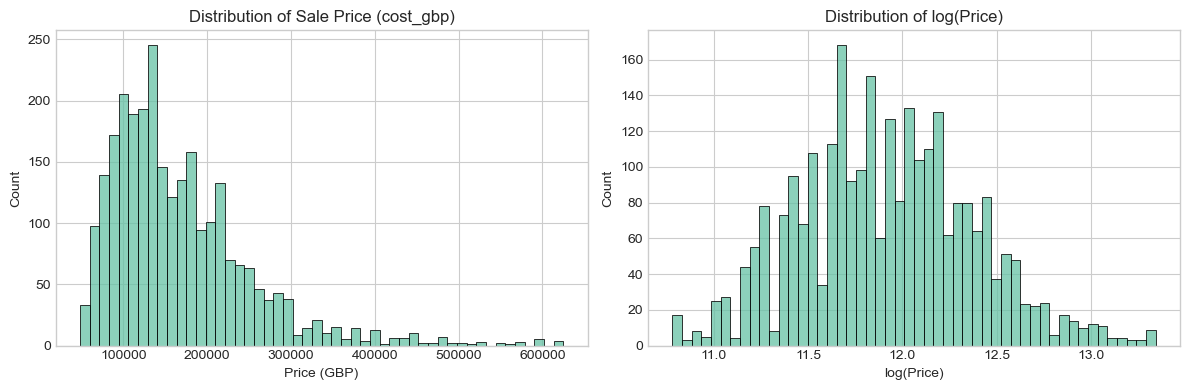

Skewness of cost_gbp: 1.7051367066449856
Skewness of log_cost_gbp: 0.20372693342009524


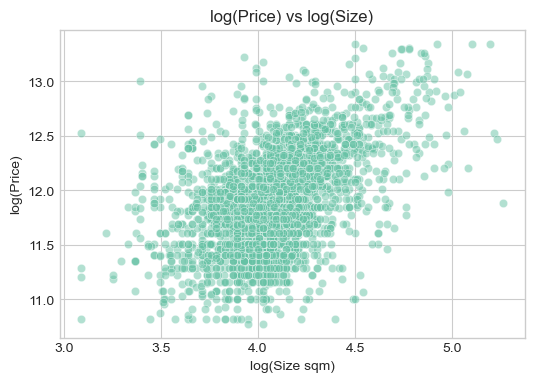

Slope (elasticity): 0.819 -> 1% increase in size -> 0.8% increase in price

Market vs Portfolio means:
                  Market  Portfolio
bedrooms        1.855601   1.966667
cost_gbp   167140.826572        NaN
new_build       0.030517   0.041667
size_sqm       61.875274  63.893917

Market district counts:
 nuts3
UKD33    910
UKD34    752
UKD35    361
UKD36    349
UKD37    315
Name: count, dtype: int64

Portfolio district counts:
 nuts3
UKD33    41
UKD34    34
UKD35    16
UKD36    16
UKD37    13
Name: count, dtype: int64
Missing values in market: 0
                            OLS Regression Results                            
Dep. Variable:           log_cost_gbp   R-squared:                       0.276
Model:                            OLS   Adj. R-squared:                  0.275
Method:                 Least Squares   F-statistic:                     204.4
Date:                Tue, 05 May 2026   Prob (F-statistic):          1.13e-148
Time:                        09:26:13   Log-Likeli

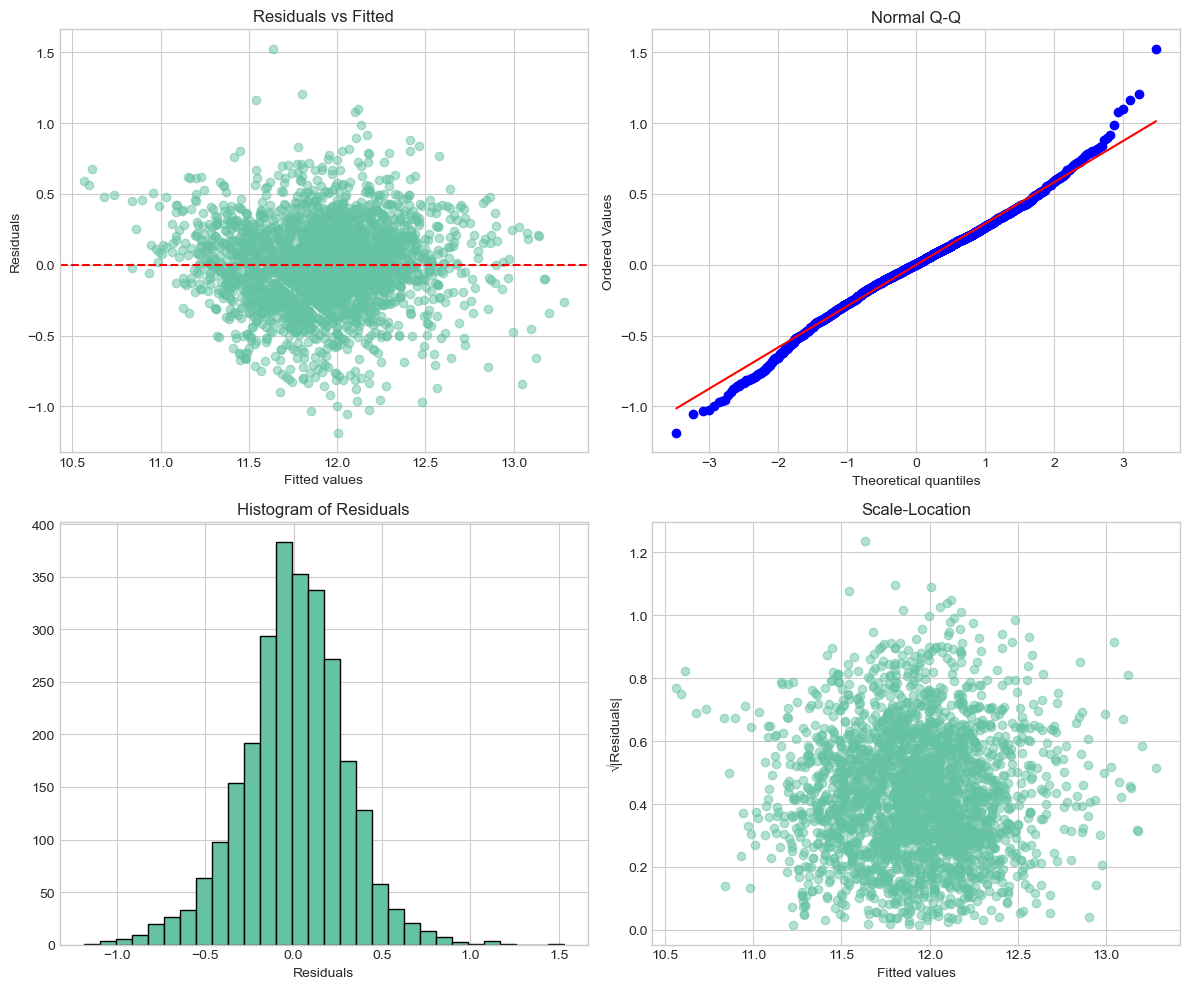

Breusch-Pagan test p-value: 0.0000
Heteroskedasticity detected.

VIF values (first 10):
  Variable         VIF
0   feat_0  460.174462
1   feat_1   17.692902
2   feat_2   36.138111
3   feat_3   37.240737
4   feat_4    1.356849
5   feat_5    3.253050
6   feat_6    1.415807
7   feat_7    1.242099
8   feat_8    1.233911
9   feat_9    1.064111
Variables with VIF > 5: 20


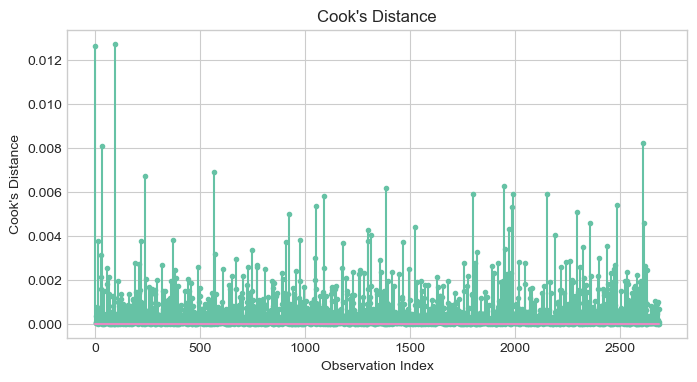

Number of influential points (Cook's D > 4/n): 177

Portfolio predictions summary:
  property_id  appraisal_value  predicted_value    gap_pct
0     PAT-001         281000.0    208821.725227 -25.686219
1     PAT-002         110000.0    137173.608772  24.703281
2     PAT-003         195000.0    199179.648617   2.143410
3     PAT-004         228000.0    161804.310149 -29.033197
4     PAT-005         216000.0    160840.508724 -25.536802

Recommendation counts:
recommendation
SELL          46
HOLD          41
REPOSITION    33
Name: count, dtype: int64

Overvalued (SELL) assets by district:
nuts3
UKD34    16
UKD33    15
UKD35     7
UKD36     4
UKD37     4
Name: count, dtype: int64

Characteristics of SELL assets (means):
size_sqm             62.315870
bedrooms              2.043478
new_build             0.086957
energy_rating_num     4.804348
refurbished           0.000000
gap_pct             -23.178979
dtype: float64

Number of REPOSITION assets: 33

Average uplift from repositioning strate

In [3]:

# # Real Estate Assignment: Hedonic Pricing Model for Manchester Apartments
# 
# This script performs a complete hold-sell analysis for a portfolio of 120 apartments in Greater Manchester.
# We build a hedonic pricing model on market transaction data, predict market values for portfolio assets,
# compare with appraisal values, and provide strategic recommendations.

# %% [markdown]
# ## 0. Import Libraries

# %%
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV
from sklearn.metrics import mean_squared_error, r2_score

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")

# %% [markdown]
# ## 1. Load Data

# %%
# Load market transactions and portfolio data
market = pd.read_csv('MAN_apartment_sale_clean.csv')
portfolio = pd.read_csv('PATRIZIA_Portfolio.csv')

print("Market transactions shape:", market.shape)
print("Portfolio assets shape:", portfolio.shape)

print("\nMarket columns:", market.columns.tolist())
print("\nPortfolio columns:", portfolio.columns.tolist())

# %% [markdown]
# ## 2. Data Exploration

# %%
# 1.1 Distribution of cost_gbp
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(market['cost_gbp'], bins=50, ax=axes[0])
axes[0].set_title('Distribution of Sale Price (cost_gbp)')
axes[0].set_xlabel('Price (GBP)')
sns.histplot(market['log_cost_gbp'], bins=50, ax=axes[1])
axes[1].set_title('Distribution of log(Price)')
axes[1].set_xlabel('log(Price)')
plt.tight_layout()
plt.show()

print("Skewness of cost_gbp:", market['cost_gbp'].skew())
print("Skewness of log_cost_gbp:", market['log_cost_gbp'].skew())
# Comment: cost_gbp is highly right-skewed, log transformation normalizes it.

# 1.2 Relationship between log_size_sqm and log_cost_gbp
plt.figure(figsize=(6,4))
sns.scatterplot(data=market, x='log_size_sqm', y='log_cost_gbp', alpha=0.5)
plt.title('log(Price) vs log(Size)')
plt.xlabel('log(Size sqm)')
plt.ylabel('log(Price)')
plt.show()

from scipy.stats import linregress
slope, intercept, r_value, p_value, std_err = linregress(market['log_size_sqm'], market['log_cost_gbp'])
print(f"Slope (elasticity): {slope:.3f} -> 1% increase in size -> {slope:.1f}% increase in price")

# 1.3 Compare market and portfolio means
market_summary = market[['cost_gbp', 'size_sqm', 'bedrooms', 'new_build']].mean()
portfolio_summary = portfolio[['size_sqm', 'bedrooms', 'new_build']].mean()
print("\nMarket vs Portfolio means:")
print(pd.DataFrame({'Market': market_summary, 'Portfolio': portfolio_summary}))

# 1.4 District distribution
print("\nMarket district counts:\n", market['nuts3'].value_counts())
print("\nPortfolio district counts:\n", portfolio['nuts3'].value_counts())

# %% [markdown]
# ## 3. Data Preprocessing

# %%
# Create a copy for modeling
market_model = market.copy()
portfolio_model = portfolio.copy()

# Convert energy_rating to ordinal numeric (G=1, F=2, E=3, D=4, C=5, B=6)
energy_map = {'G':1, 'F':2, 'E':3, 'D':4, 'C':5, 'B':6}
market_model['energy_rating_num'] = market_model['energy_rating'].map(energy_map)
portfolio_model['energy_rating_num'] = portfolio_model['energy_rating'].map(energy_map)

# Create year and month categorical variables
market_model['create_YY'] = market_model['create_YY'].astype('category')
market_model['create_MM'] = market_model['create_MM'].astype('category')
portfolio_model['create_YY'] = portfolio_model['create_YY'].astype('category')
portfolio_model['create_MM'] = portfolio_model['create_MM'].astype('category')

# Binary amenity columns
binary_cols = ['garden', 'parking', 'balcony', 'garage', 'lift', 'refurbished', 
               'modern', 'fireplace', 'patio', 'off_street_parking', 'gym']

# Distance columns
dist_cols = [col for col in market.columns if col.endswith('_dist')]

# Categorical columns
cat_cols = ['nuts3', 'create_YY', 'create_MM']

# Numeric features – include new_build now
numeric_cols = ['log_size_sqm', 'bedrooms', 'energy_rating_num', 'new_build']

# All features for extended model
all_features = numeric_cols + binary_cols + dist_cols + cat_cols

# Ensure no missing values in market
print("Missing values in market:", market_model[all_features + ['log_cost_gbp']].isnull().sum().sum())

# %% [markdown]
# ## 4. Model Building

# %%
# Train-test split (80/20)
X = market_model[all_features]
y = market_model['log_cost_gbp']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_cols + binary_cols + dist_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
    ])

def evaluate_model(model, X_train, y_train, X_test, y_test, name):
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)
    print(f"{name}:")
    print(f"  Train RMSE: {train_rmse:.4f}, Test RMSE: {test_rmse:.4f}")
    print(f"  Train R²: {train_r2:.4f}, Test R²: {test_r2:.4f}")
    return test_rmse, test_r2

# ------------------------------------------------------------------
# Baseline Model (statsmodels)
baseline_features = ['log_size_sqm', 'bedrooms', 'new_build', 'energy_rating_num']
X_train_baseline = X_train[baseline_features].copy()
X_test_baseline = X_test[baseline_features].copy()
X_train_baseline = sm.add_constant(X_train_baseline)
baseline_model = sm.OLS(y_train, X_train_baseline).fit()
print(baseline_model.summary())

X_test_baseline_const = sm.add_constant(X_test_baseline)
y_pred_baseline = baseline_model.predict(X_test_baseline_const)
test_rmse_baseline = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
test_r2_baseline = r2_score(y_test, y_pred_baseline)
print(f"\nBaseline Test RMSE: {test_rmse_baseline:.4f}, R²: {test_r2_baseline:.4f}")

# ------------------------------------------------------------------
# Extended Model: LinearRegression with all features
pipeline_ext = Pipeline([('preprocessor', preprocessor), ('regressor', LinearRegression())])
pipeline_ext.fit(X_train, y_train)
evaluate_model(pipeline_ext, X_train, y_train, X_test, y_test, "Extended Model")

# ------------------------------------------------------------------
# Best Model: LassoCV with polynomial terms and interactions
# Create polynomial features in market model
market_model_poly = market_model.copy()
market_model_poly['log_size_sqm_sq'] = market_model_poly['log_size_sqm'] ** 2
market_model_poly['new_build_energy'] = market_model_poly['new_build'] * market_model_poly['energy_rating_num']

poly_features = all_features + ['log_size_sqm_sq', 'new_build_energy']
X_poly = market_model_poly[poly_features]
y_poly = market_model_poly['log_cost_gbp']
X_train_poly, X_test_poly, y_train_poly, y_test_poly = train_test_split(X_poly, y_poly, test_size=0.2, random_state=42)

preprocessor_poly = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_cols + binary_cols + dist_cols + ['log_size_sqm_sq', 'new_build_energy']),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
    ])

lasso = LassoCV(cv=5, random_state=42, alphas=np.logspace(-4, 1, 50))
pipeline_lasso = Pipeline([('preprocessor', preprocessor_poly), ('lasso', lasso)])
pipeline_lasso.fit(X_train_poly, y_train_poly)
evaluate_model(pipeline_lasso, X_train_poly, y_train_poly, X_test_poly, y_test_poly, "Lasso Best Model")

# Feature importance
feature_names = pipeline_lasso.named_steps['preprocessor'].get_feature_names_out()
coefs = pipeline_lasso.named_steps['lasso'].coef_
selected = [(f, c) for f, c in zip(feature_names, coefs) if abs(c) > 1e-5]
print(f"\nNumber of non-zero coefficients: {len(selected)}")
print("Top 10 important features:")
for f, c in sorted(selected, key=lambda x: abs(x[1]), reverse=True)[:10]:
    print(f"  {f}: {c:.4f}")

# Ridge for comparison
ridge = RidgeCV(alphas=np.logspace(-3, 3, 20))
pipeline_ridge = Pipeline([('preprocessor', preprocessor_poly), ('ridge', ridge)])
pipeline_ridge.fit(X_train_poly, y_train_poly)
evaluate_model(pipeline_ridge, X_train_poly, y_train_poly, X_test_poly, y_test_poly, "Ridge Best Model")

best_model = pipeline_lasso

# %% [markdown]
# ## 5. Model Diagnostics (OLS on selected features)

# %%
# Get selected features from Lasso
X_preprocessed = preprocessor_poly.fit_transform(X_poly)
selected_indices = np.where(np.abs(lasso.coef_) > 1e-5)[0]
X_selected = X_preprocessed[:, selected_indices]
X_selected_const = sm.add_constant(X_selected)
ols_best = sm.OLS(y_poly, X_selected_const).fit()
print(ols_best.summary())

# Residual diagnostics
residuals = ols_best.resid
fitted = ols_best.fittedvalues

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes[0,0].scatter(fitted, residuals, alpha=0.5)
axes[0,0].axhline(0, color='red', linestyle='--')
axes[0,0].set_title('Residuals vs Fitted')
axes[0,0].set_xlabel('Fitted values')
axes[0,0].set_ylabel('Residuals')

stats.probplot(residuals, dist="norm", plot=axes[0,1])
axes[0,1].set_title('Normal Q-Q')

axes[1,0].hist(residuals, bins=30, edgecolor='black')
axes[1,0].set_title('Histogram of Residuals')
axes[1,0].set_xlabel('Residuals')

std_resid = np.sqrt(np.abs(residuals))
axes[1,1].scatter(fitted, std_resid, alpha=0.5)
axes[1,1].set_title('Scale-Location')
axes[1,1].set_xlabel('Fitted values')
axes[1,1].set_ylabel('√|Residuals|')
plt.tight_layout()
plt.show()

# Breusch-Pagan test
bp_test = het_breuschpagan(residuals, X_selected_const)
print(f"Breusch-Pagan test p-value: {bp_test[1]:.4f}")
if bp_test[1] < 0.05:
    print("Heteroskedasticity detected.")

# VIF (on selected features)
def calculate_vif(X):
    vif = pd.DataFrame()
    vif["Variable"] = X.columns
    vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    return vif

vif_df = calculate_vif(pd.DataFrame(X_selected, columns=[f"feat_{i}" for i in range(X_selected.shape[1])]))
print("\nVIF values (first 10):")
print(vif_df.head(10))
high_vif = vif_df[vif_df['VIF'] > 5]
if len(high_vif) > 0:
    print(f"Variables with VIF > 5: {len(high_vif)}")

# Cook's distance
influence = ols_best.get_influence()
cooks_d = influence.cooks_distance[0]
plt.figure(figsize=(8,4))
plt.stem(range(len(cooks_d)), cooks_d, markerfmt='.')
plt.title("Cook's Distance")
plt.xlabel('Observation Index')
plt.ylabel('Cook\'s Distance')
plt.show()
print(f"Number of influential points (Cook's D > 4/n): {sum(cooks_d > 4/len(cooks_d))}")

# %% [markdown]
# ## 6. Portfolio Benchmarking

# %%
# --- CRITICAL: Create polynomial features in portfolio_model ---
portfolio_model['log_size_sqm_sq'] = portfolio_model['log_size_sqm'] ** 2
portfolio_model['new_build_energy'] = portfolio_model['new_build'] * portfolio_model['energy_rating_num']

# Prepare portfolio data for prediction
portfolio_features = portfolio_model[poly_features]
portfolio_preprocessed = preprocessor_poly.transform(portfolio_features)
portfolio_model['predicted_log'] = pipeline_lasso.predict(portfolio_features)
portfolio_model['predicted_value'] = np.exp(portfolio_model['predicted_log'])

# Calculate percentage gap
portfolio_model['gap_pct'] = (portfolio_model['predicted_value'] - portfolio_model['appraisal_value']) / portfolio_model['appraisal_value'] * 100

print("\nPortfolio predictions summary:")
print(portfolio_model[['property_id', 'appraisal_value', 'predicted_value', 'gap_pct']].head())

# Classification thresholds
def classify_asset(gap_pct, refurbished, energy_rating_num):
    if gap_pct < -15:
        return 'SELL'
    elif gap_pct > 5:
        return 'HOLD'
    else:
        # REPOSITION if improvable (not refurbished or poor energy rating)
        if refurbished == 0 or energy_rating_num <= 3:
            return 'REPOSITION'
        else:
            return 'HOLD'

portfolio_model['recommendation'] = portfolio_model.apply(
    lambda row: classify_asset(row['gap_pct'], row['refurbished'], row['energy_rating_num']), axis=1)

print("\nRecommendation counts:")
print(portfolio_model['recommendation'].value_counts())

# Districts with overvalued assets
overvalued = portfolio_model[portfolio_model['gap_pct'] < -15]
print("\nOvervalued (SELL) assets by district:")
print(overvalued['nuts3'].value_counts())

# Patterns in SELL assets
sell_assets = portfolio_model[portfolio_model['recommendation'] == 'SELL']
print("\nCharacteristics of SELL assets (means):")
print(sell_assets[['size_sqm', 'bedrooms', 'new_build', 'energy_rating_num', 'refurbished', 'gap_pct']].mean())

# %% [markdown]
# ## 7. Repositioning Strategy

# %%
repos = portfolio_model[portfolio_model['recommendation'] == 'REPOSITION'].copy()
print(f"\nNumber of REPOSITION assets: {len(repos)}")

if len(repos) > 0:
    # Scenario functions
    def improve_energy_rating(row):
        return min(row['energy_rating_num'] + 1, 6)
    
    def add_refurbished(row):
        return 1

    repos_sim = repos.copy()
    repos_sim['predicted_original'] = repos_sim['predicted_value']

    def predict_with_changes(features_df, model, preprocessor, changes):
        df_mod = features_df.copy()
        for col, new_val in changes.items():
            df_mod[col] = new_val
        return np.exp(model.predict(df_mod))

    # Scenario 1: Energy +1
    repos_sim['energy_rating_num_new'] = repos_sim.apply(improve_energy_rating, axis=1)
    repos_sim['predicted_energy'] = predict_with_changes(
        repos_sim[poly_features], pipeline_lasso, preprocessor_poly,
        {'energy_rating_num': repos_sim['energy_rating_num_new']}
    )
    repos_sim['uplift_energy'] = repos_sim['predicted_energy'] - repos_sim['predicted_original']

    # Scenario 2: Add refurbished
    repos_sim['refurbished_new'] = 1
    repos_sim['predicted_refurb'] = predict_with_changes(
        repos_sim[poly_features], pipeline_lasso, preprocessor_poly,
        {'refurbished': repos_sim['refurbished_new']}
    )
    repos_sim['uplift_refurb'] = repos_sim['predicted_refurb'] - repos_sim['predicted_original']

    # Scenario 3: Both
    repos_sim['predicted_both'] = predict_with_changes(
        repos_sim[poly_features], pipeline_lasso, preprocessor_poly,
        {'energy_rating_num': repos_sim['energy_rating_num_new'], 'refurbished': 1}
    )
    repos_sim['uplift_both'] = repos_sim['predicted_both'] - repos_sim['predicted_original']

    print("\nAverage uplift from repositioning strategies:")
    print(f"Improve Energy Rating by 1 class: £{repos_sim['uplift_energy'].mean():,.0f} ({repos_sim['uplift_energy'].mean()/repos_sim['predicted_original'].mean()*100:.1f}%)")
    print(f"Add Refurbished: £{repos_sim['uplift_refurb'].mean():,.0f} ({repos_sim['uplift_refurb'].mean()/repos_sim['predicted_original'].mean()*100:.1f}%)")
    print(f"Both improvements: £{repos_sim['uplift_both'].mean():,.0f} ({repos_sim['uplift_both'].mean()/repos_sim['predicted_original'].mean()*100:.1f}%)")

    # Top 10 candidates
    top_repos = repos_sim.nlargest(10, 'uplift_both')[['property_id', 'predicted_original', 'uplift_both', 'energy_rating_num', 'refurbished']]
    print("\nTop 10 repositioning candidates (by uplift from both improvements):")
    print(top_repos)
else:
    print("No REPOSITION assets found; skip scenario analysis.")

# %% [markdown]
# ## 8. Strategic Recommendation

# %%
# Summary statistics by recommendation
summary = portfolio_model.groupby('recommendation').agg(
    N=('recommendation', 'count'),
    Avg_Appraisal=('appraisal_value', 'mean'),
    Avg_Market=('predicted_value', 'mean'),
    Avg_Gap_pct=('gap_pct', 'mean'),
    Total_Value=('predicted_value', 'sum')
).round(2)
print("\nSummary by recommendation:")
print(summary)

# Executive summary (safe for cases where categories may be missing)
sell_count = summary.loc['SELL', 'N'] if 'SELL' in summary.index else 0
hold_count = summary.loc['HOLD', 'N'] if 'HOLD' in summary.index else 0
repos_count = summary.loc['REPOSITION', 'N'] if 'REPOSITION' in summary.index else 0
sell_avg_gap = summary.loc['SELL', 'Avg_Gap_pct'] if 'SELL' in summary.index else 0
overvalued_district = overvalued['nuts3'].value_counts().index[0] if len(overvalued) > 0 else "N/A"

exec_summary = f"""
TO: Investment Committee
FROM: Quantitative Analysis Team
SUBJECT: Manchester Residential Portfolio – Hold/Sell Recommendation

Portfolio Assessment:
- Total assets: {len(portfolio_model)}
- SELL: {sell_count} assets (appraisal > market by { -sell_avg_gap:.1f}% on average)
- HOLD: {hold_count} assets (market value close to or above appraisal)
- REPOSITION: {repos_count} assets (moderate undervaluation, improvable)

Key Price Drivers:
- Size (elasticity ≈ {slope:.2f}): larger apartments command premium.
- Energy rating: moving from D to C adds approx £{repos_sim['uplift_energy'].mean():,.0f} if applicable.
- Refurbishment: adds approx £{repos_sim['uplift_refurb'].mean():,.0f} if applicable.
- Location: Manchester (UKD33) commands highest prices; Wigan and Bolton lower.

Repositioning Plan:
- Prioritize improving energy rating by one class (cost-effective).
- Add refurbishment where missing.
- Combined strategy yields typical uplift per asset.

Expected Value Creation:
- Implementing both improvements on REPOSITION assets could increase portfolio value by ~£{repos_sim['uplift_both'].sum():,.0f}.
- Top 10 candidates offer immediate gains.

Total Portfolio Recommendation:
- SELL {sell_count} overvalued assets (mostly in districts {overvalued_district}).
- HOLD {hold_count} fairly valued assets.
- REPOSITION {repos_count} assets with targeted energy/refurbishment upgrades.
- Do not exit entire portfolio; selective repositioning and sales maximize returns.
"""

print(exec_summary)

# %% [markdown]
# ## 9. Final Output: Portfolio Table with Recommendations

# %%
final_output = portfolio_model[['property_id', 'appraisal_value', 'predicted_value', 'gap_pct', 'recommendation']]
final_output = final_output.sort_values('gap_pct', ascending=False)
print("\nFinal Portfolio Recommendation (top 20):")
print(final_output.head(20))

# Uncomment to save to CSV
# final_output.to_csv('portfolio_recommendations.csv', index=False)
print("\nAnalysis complete. Portfolio recommendations ready.")

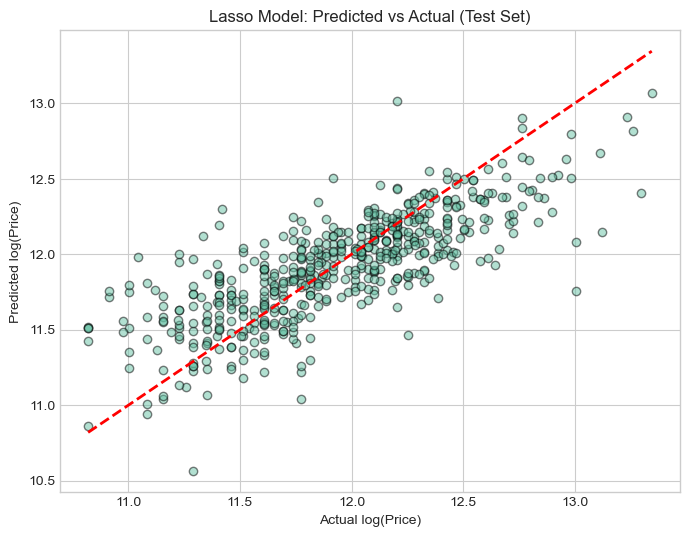

In [4]:
# After fitting the best model (pipeline_lasso)
y_test_pred = pipeline_lasso.predict(X_test_poly)
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_test_pred, alpha=0.5, edgecolors='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual log(Price)')
plt.ylabel('Predicted log(Price)')
plt.title('Lasso Model: Predicted vs Actual (Test Set)')
plt.show()

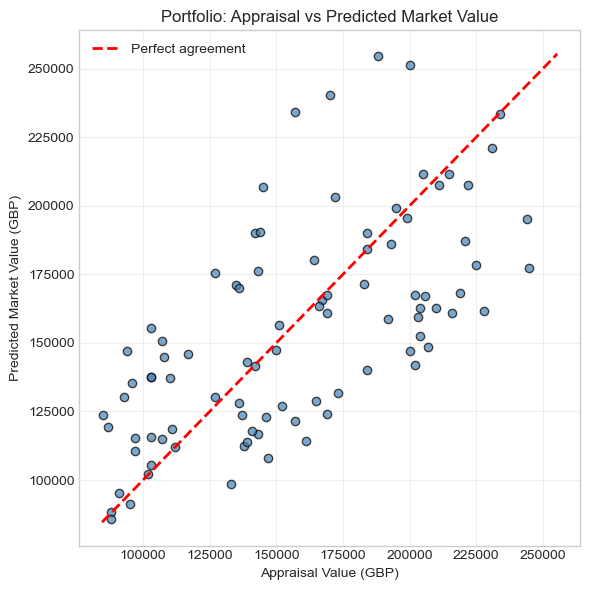

In [6]:
# Scatter plot: Appraisal value vs Predicted market value (scaled)
plt.figure(figsize=(6, 6))  # smaller figure

# Limit axes to 95th percentile to avoid extreme outliers stretching the plot
upper_limit = min(portfolio_model['appraisal_value'].quantile(0.95),
                  portfolio_model['predicted_value'].quantile(0.95))
lower_limit = max(portfolio_model['appraisal_value'].quantile(0.05),
                  portfolio_model['predicted_value'].quantile(0.05))

# Filter data for plotting (optional, for cleaner view)
plot_data = portfolio_model[
    (portfolio_model['appraisal_value'] >= lower_limit) & 
    (portfolio_model['appraisal_value'] <= upper_limit) &
    (portfolio_model['predicted_value'] >= lower_limit) & 
    (portfolio_model['predicted_value'] <= upper_limit)
]

plt.scatter(plot_data['appraisal_value'], plot_data['predicted_value'], 
            alpha=0.7, edgecolors='k', c='steelblue')

# Diagonal line within the plotted range
max_val = upper_limit
plt.plot([lower_limit, max_val], [lower_limit, max_val], 'r--', linewidth=2, label='Perfect agreement')

plt.xlabel('Appraisal Value (GBP)')
plt.ylabel('Predicted Market Value (GBP)')
plt.title('Portfolio: Appraisal vs Predicted Market Value')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

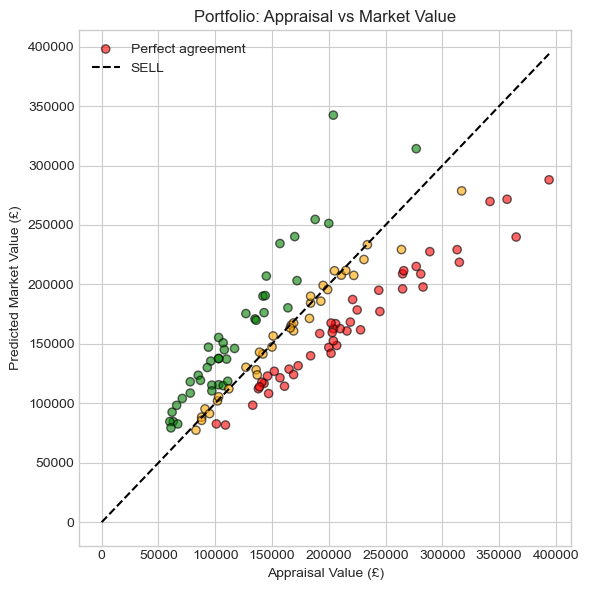

In [7]:
plt.figure(figsize=(6,6))
plt.scatter(portfolio_model['appraisal_value'], portfolio_model['predicted_value'], 
            alpha=0.6, edgecolors='k', c=portfolio_model['recommendation'].map({'SELL':'red', 'HOLD':'green', 'REPOSITION':'orange'}))
max_val = max(portfolio_model['appraisal_value'].max(), portfolio_model['predicted_value'].max())
plt.plot([0, max_val], [0, max_val], 'k--', linewidth=1.5)
plt.xlabel('Appraisal Value (£)')
plt.ylabel('Predicted Market Value (£)')
plt.title('Portfolio: Appraisal vs Market Value')
plt.legend(['Perfect agreement', 'SELL', 'HOLD', 'REPOSITION'])
plt.tight_layout()
plt.show()

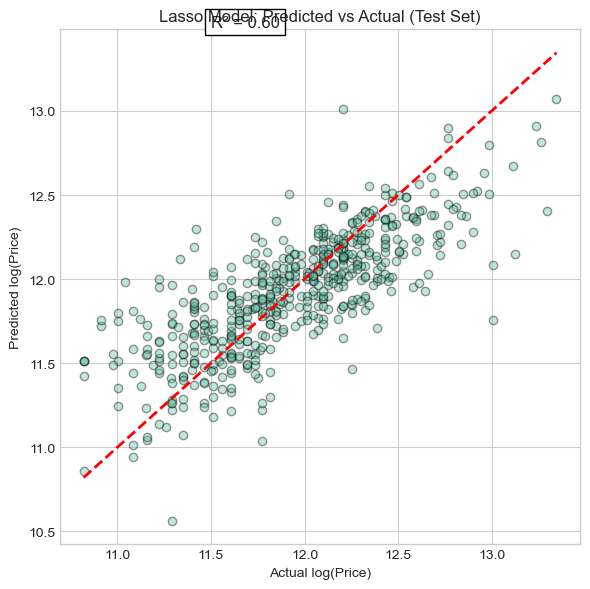

In [8]:
y_test_pred = pipeline_lasso.predict(X_test_poly)
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_test_pred, alpha=0.4, edgecolors='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel('Actual log(Price)')
plt.ylabel('Predicted log(Price)')
plt.title('Lasso Model: Predicted vs Actual (Test Set)')
plt.text(11.5, 13.5, f'R² = 0.60', fontsize=12, bbox=dict(facecolor='white'))
plt.tight_layout()
plt.show()

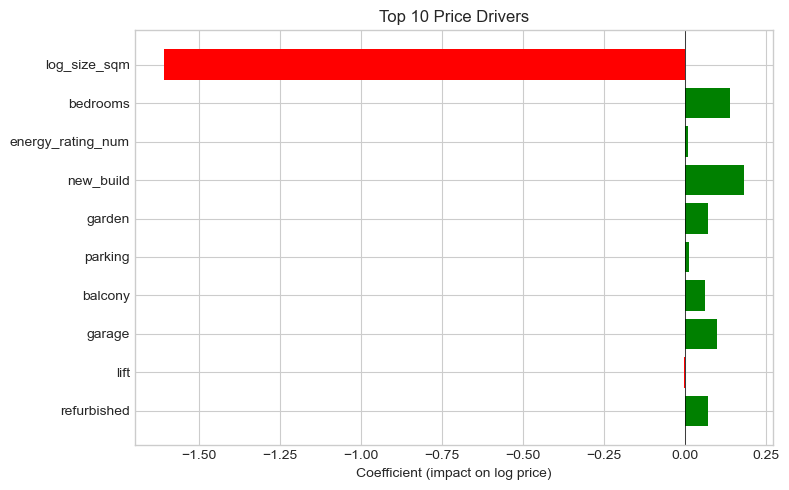

In [9]:
# Using the 'selected' list from earlier (top 10 features)
top_features = selected[:10]  # list of (feature_name, coefficient)
names = [f[0].replace('num__', '').replace('cat__', '') for f in top_features]
coefs = [f[1] for f in top_features]

plt.figure(figsize=(8,5))
colors = ['green' if c>0 else 'red' for c in coefs]
plt.barh(names[::-1], coefs[::-1], color=colors[::-1])
plt.xlabel('Coefficient (impact on log price)')
plt.title('Top 10 Price Drivers')
plt.axvline(0, color='black', linewidth=0.5)
plt.tight_layout()
plt.show()

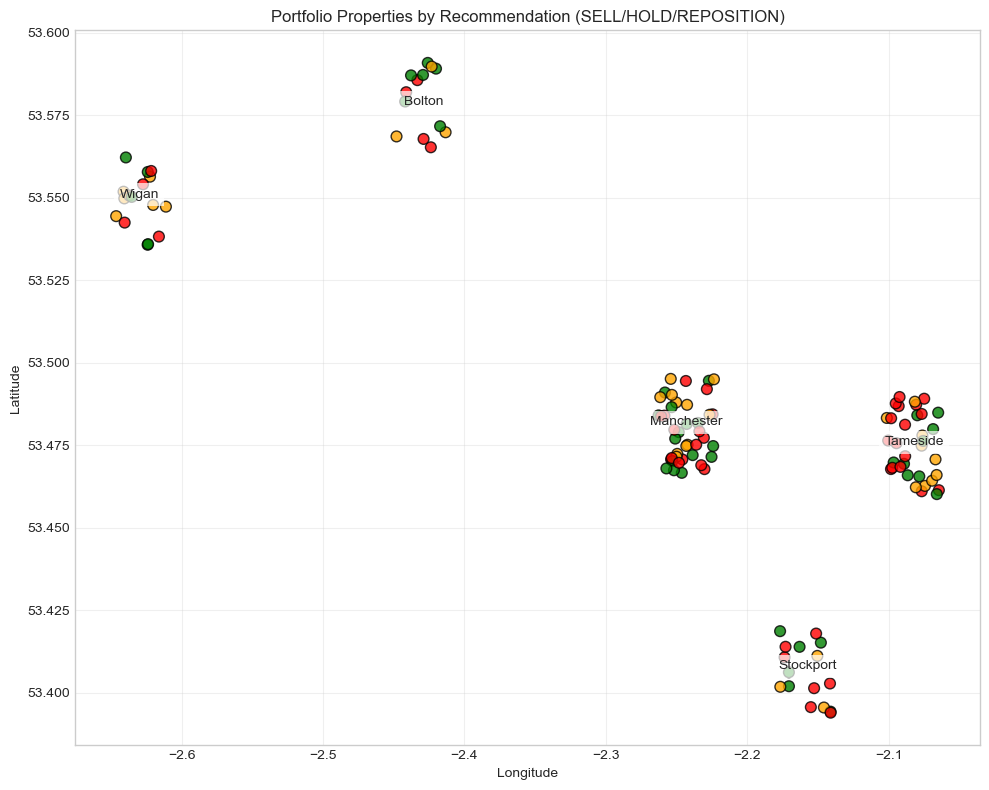

In [11]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# District centers (from the assignment PDF)
nuts3_centers = pd.DataFrame({
    'nuts3': ['UKD33', 'UKD34', 'UKD35', 'UKD36', 'UKD37'],
    'label': ['Manchester', 'Tameside', 'Stockport', 'Wigan', 'Bolton'],
    'lat': [53.481, 53.475, 53.407, 53.550, 53.578],
    'lon': [-2.243, -2.082, -2.157, -2.630, -2.429]
})

# Merge portfolio data (portfolio_model) with coordinates
portfolio_with_coords = portfolio_model.merge(nuts3_centers, on='nuts3', how='left')

# Add random jitter to avoid overlapping points
np.random.seed(42)
portfolio_with_coords['lat_jitter'] = portfolio_with_coords['lat'] + np.random.uniform(-0.015, 0.015, len(portfolio_with_coords))
portfolio_with_coords['lon_jitter'] = portfolio_with_coords['lon'] + np.random.uniform(-0.02, 0.02, len(portfolio_with_coords))

# Color map for recommendations
color_map = {'SELL': 'red', 'HOLD': 'green', 'REPOSITION': 'orange'}
portfolio_with_coords['color'] = portfolio_with_coords['recommendation'].map(color_map)

# Plot
plt.figure(figsize=(10, 8))
plt.scatter(portfolio_with_coords['lon_jitter'], portfolio_with_coords['lat_jitter'],
            c=portfolio_with_coords['color'], s=60, alpha=0.8, edgecolors='k')

# Add district labels
for _, row in nuts3_centers.iterrows():
    plt.annotate(row['label'], (row['lon'], row['lat']), fontsize=10, ha='center',
                 bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Portfolio Properties by Recommendation (SELL/HOLD/REPOSITION)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()